In [ ]:
'''Develop automated Python scripts that generate customizable, dynamic reports combining model insights, performance summaries, and fairness analysis in the context of admission decisions.'''

'Design and implement deployment-ready machine learning pipelines that automate data preprocessing, model validation, and prediction generation, ensuring reproducibility and reliability for admission predictions.'

In [2]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score


In [3]:
# load dataset and inspect structure
df = pd.read_csv('Adm.csv')
print(df.shape)
print(df.head())


(1000, 12)
   Serial No.  GRE Score  ...                             University_Name  region
0           1        337  ...    Indian Institute of Technology Kharagpur    East
1           2        324  ...  National Institute of Technology Karnataka   South
2           3        316  ...                          Gujarat University    West
3           4        322  ...                        Jamia Millia Islamia   North
4           5        314  ...                        Jamia Millia Islamia   North

[5 rows x 12 columns]


In [4]:
# create binary admission target
df['Admit'] = (df['Chance of Admit'] >= 0.70).astype(int)
print(df['Admit'].value_counts())


Admit
1    572
0    428
Name: count, dtype: int64


In [5]:
# split features and train test sets
feature_cols = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
X = df[feature_cols]
y = df['Admit']
X_train, X_test, y_train, y_test, df_train, df_test = train_test_split(X, y, df, test_size=0.2, random_state=42)
print("train size:", len(X_train), "test size:", len(X_test))


train size: 800 test size: 200


In [6]:
# train classification model
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]
print("model training completed")


model training completed


In [7]:
# generate dynamic performance report
def generate_performance_report(y_true, y_pred, y_prob):
    metrics = {
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred),
        'recall': recall_score(y_true, y_pred),
        'f1_score': f1_score(y_true, y_pred),
        'roc_auc': roc_auc_score(y_true, y_prob)
    }
    print("=== performance summary ===")
    for k, v in metrics.items():
        print(f"{k}: {v:.4f}")
    return metrics

perf_metrics = generate_performance_report(y_test, y_pred, y_prob)


=== performance summary ===
accuracy: 0.8900
precision: 0.8729
recall: 0.9364
f1_score: 0.9035
roc_auc: 0.9602


In [8]:
# generate model insights and feature importance
def generate_feature_insights(model, feature_names):
    importance = pd.DataFrame({
        'feature': feature_names,
        'importance': model.feature_importances_
    })
    importance = importance.sort_values(by='importance', ascending=False)
    print("=== feature importance insights ===")
    print(importance)
    return importance

feat_importance = generate_feature_insights(model, feature_cols)


=== feature importance insights ===
             feature  importance
5               CGPA    0.487137
0          GRE Score    0.153125
1        TOEFL Score    0.121807
4                LOR    0.111838
3                SOP    0.054591
2  University Rating    0.036640
6           Research    0.034862


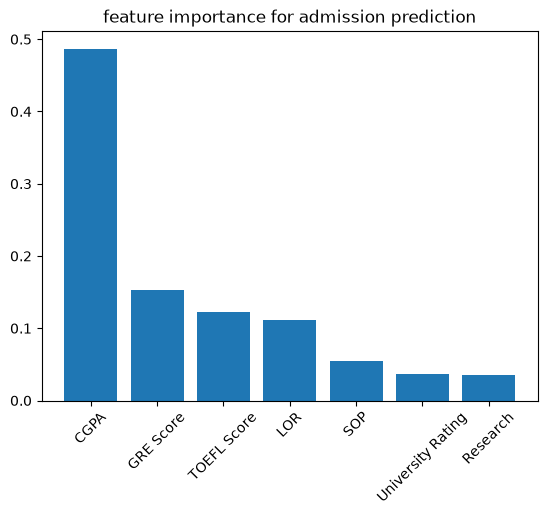

In [9]:
# plot feature importance
plt.figure()
plt.bar(feat_importance['feature'], feat_importance['importance'])
plt.xticks(rotation=45)
plt.title('feature importance for admission prediction')
plt.show()


In [10]:
# generate fairness analysis across groups
def analyze_fairness(df_subset, y_true, y_pred, group_col='region'):
    analysis_df = df_subset.copy()
    analysis_df['actual'] = y_true.values
    analysis_df['predicted'] = y_pred
    
    fairness_summary = analysis_df.groupby(group_col).agg(
        total_applicants=('predicted', 'count'),
        selection_rate=('predicted', 'mean'),
        actual_rate=('actual', 'mean')
    ).reset_index()
    
    print("=== fairness analysis by group ===")
    print(fairness_summary)
    return fairness_summary

fairness_res = analyze_fairness(df_test, y_test, y_pred, group_col='region')


=== fairness analysis by group ===
      region  total_applicants  selection_rate  actual_rate
0    Central                 3        0.666667     0.666667
1       East                12        0.750000     0.750000
2      North                66        0.621212     0.590909
3  Northeast                 6        1.000000     0.833333
4      South                84        0.547619     0.511905
5       West                29        0.482759     0.413793


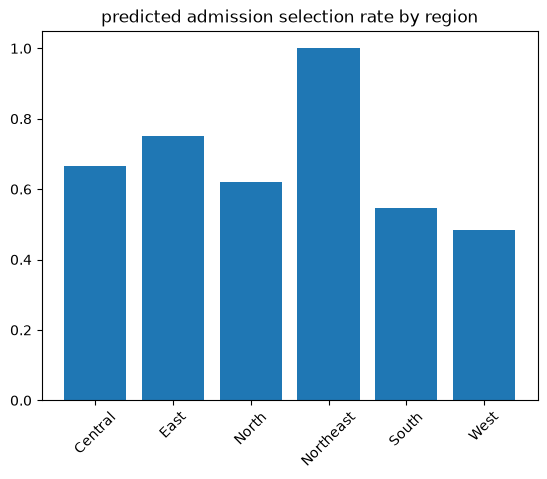

In [11]:
# plot fairness selection rates by region
plt.figure()
plt.bar(fairness_res['region'], fairness_res['selection_rate'])
plt.xticks(rotation=45)
plt.title('predicted admission selection rate by region')
plt.show()


In [12]:
# automated dynamic admission report generator
def automated_admission_pipeline_report(df, target_threshold=0.70, group_col='region'):
    data = df.copy()
    data['Admit'] = (data['Chance of Admit'] >= target_threshold).astype(int)
    X = data[feature_cols]
    y = data['Admit']
    X_tr, X_te, y_tr, y_te, d_tr, d_te = train_test_split(X, y, data, test_size=0.2, random_state=42)
    
    clf = RandomForestClassifier(n_estimators=100, random_state=42)
    clf.fit(X_tr, y_tr)
    preds = clf.predict(X_te)
    probs = clf.predict_proba(X_te)[:, 1]
    
    p_metrics = generate_performance_report(y_te, preds, probs)
    f_insights = generate_feature_insights(clf, feature_cols)
    f_fairness = analyze_fairness(d_te, y_te, preds, group_col=group_col)
    
    return {
        'metrics': p_metrics,
        'importance': f_insights,
        'fairness': f_fairness
    }

full_report = automated_admission_pipeline_report(df, target_threshold=0.70)


=== performance summary ===
accuracy: 0.8900
precision: 0.8729
recall: 0.9364
f1_score: 0.9035
roc_auc: 0.9602
=== feature importance insights ===
             feature  importance
5               CGPA    0.487137
0          GRE Score    0.153125
1        TOEFL Score    0.121807
4                LOR    0.111838
3                SOP    0.054591
2  University Rating    0.036640
6           Research    0.034862
=== fairness analysis by group ===
      region  total_applicants  selection_rate  actual_rate
0    Central                 3        0.666667     0.666667
1       East                12        0.750000     0.750000
2      North                66        0.621212     0.590909
3  Northeast                 6        1.000000     0.833333
4      South                84        0.547619     0.511905
5       West                29        0.482759     0.413793
